<a href="https://colab.research.google.com/github/Ag3-S/Neural-Networks-Lab/blob/main/Experiment_8_pytorch_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Convolutional Neural Networks: Application

In this notebook, you will:

- Implement helper functions that you will use when implementing a **PyTorch** model
- Implement a fully functioning ConvNet using **PyTorch**

**After this assignment you will be able to:**

- Build and train a ConvNet in **PyTorch** for a classification problem

We assume here that you are already familiar with **PyTorch**. If you are not, please refer to previous notebooks.

##  PyTorch model

We will load essential files

In [11]:
import math
import numpy as np
import h5py
import matplotlib.pyplot as plt
import scipy
from PIL import Image
from scipy import ndimage
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

%matplotlib inline
np.random.seed(1)
torch.manual_seed(1) # PyTorch seed for reproducibility

##Inspects the h5 file named as test_sign, but it has both the train and test cases

In [12]:
# 1. Load and inspect H5 file
file_path = r"/content/test_signs.h5"  # Change path

with h5py.File(file_path, "r") as f:

    print("HDF5 FILE CONTENTS")
    print("-" * 50)

    def inspect(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"{name}: Shape={obj.shape}, dtype={obj.dtype}")

    f.visititems(inspect)

    # Load all top-level datasets
    data = {
        key: np.array(f[key])
        for key in f.keys()
        if isinstance(f[key], h5py.Dataset)
    }

# 2. Visualize available data
print("\nLoaded datasets:", list(data.keys()))

for name, arr in data.items():
    print(f"{name}: {arr.shape}, {arr.dtype}")



HDF5 FILE CONTENTS
--------------------------------------------------
list_classes: Shape=(6,), dtype=int64
test_set_x: Shape=(120, 64, 64, 3), dtype=uint8
test_set_y: Shape=(120,), dtype=int64

Loaded datasets: ['list_classes', 'test_set_x', 'test_set_y']
list_classes: (6,), int64
test_set_x: (120, 64, 64, 3), uint8
test_set_y: (120,), int64


Dataset shape: (120, 64, 64, 3)
Labels shape: (120,)
Classes: [0 1 2 3 4 5]


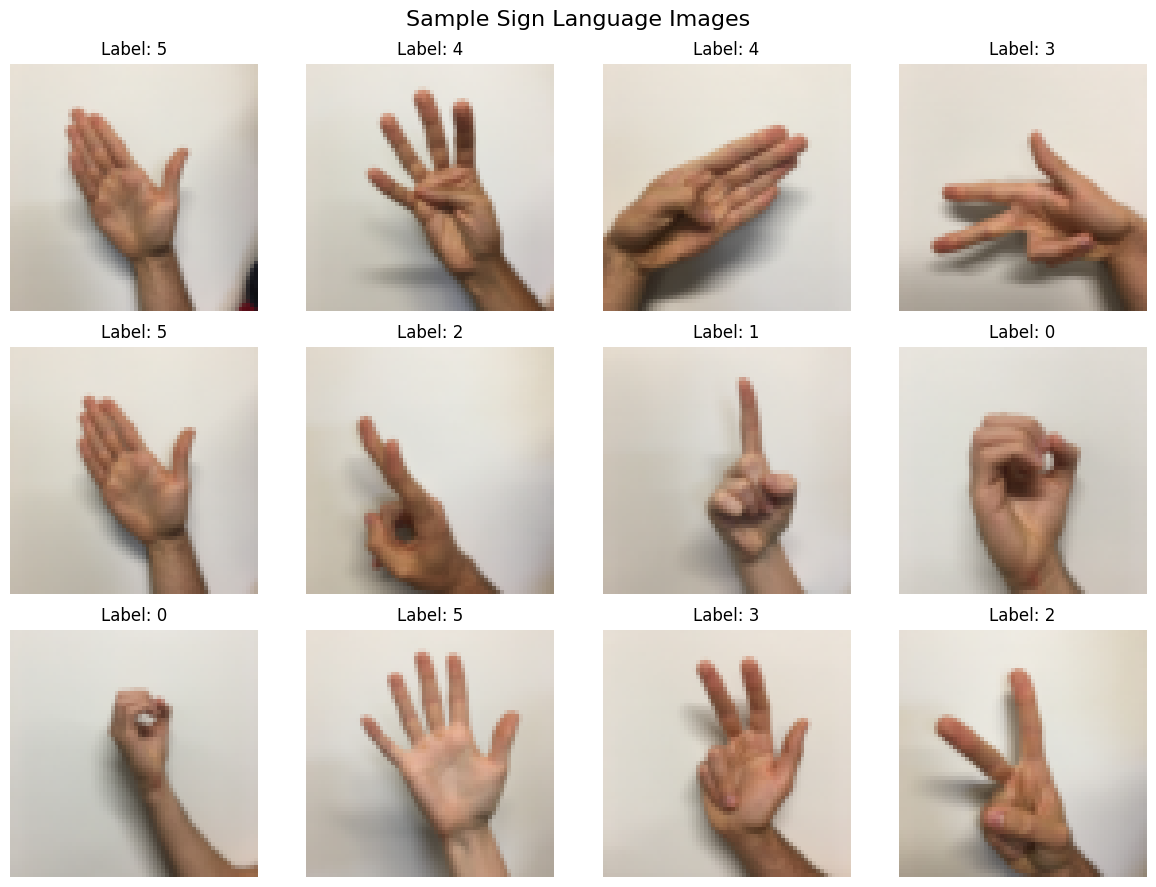


Class Distribution:
Class 0: 20 images
Class 1: 20 images
Class 2: 20 images
Class 3: 20 images
Class 4: 20 images
Class 5: 20 images


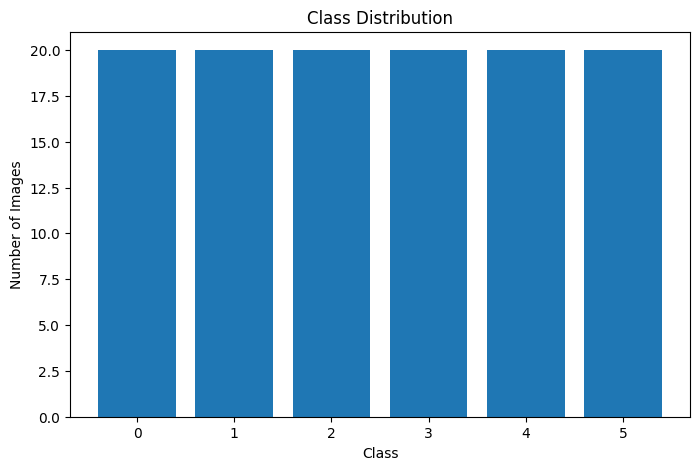


Train-Test Split Results
----------------------------------------
X_train: (96, 64, 64, 3)
y_train: (96,)
X_test: (24, 64, 64, 3)
y_test: (24,)


In [13]:

# 1. Extract images, labels and classes

X = data["test_set_x"]
y = data["test_set_y"]
classes = data["list_classes"]

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)
print("Classes:", classes)


# 2. Visualize sample images

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

indices = np.random.choice(len(X), 12, replace=False)

for ax, idx in zip(axes.flat, indices):
    ax.imshow(X[idx])
    ax.set_title(f"Label: {y[idx]}")
    ax.axis("off")

plt.suptitle("Sample Sign Language Images", fontsize=16)
plt.tight_layout()
plt.show()


# 3. Analyze class distribution

unique_classes, counts = np.unique(y, return_counts=True)

print("\nClass Distribution:")
for cls, count in zip(unique_classes, counts):
    print(f"Class {cls}: {count} images")

plt.figure(figsize=(8, 5))
plt.bar(unique_classes, counts)
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("Class Distribution")
plt.xticks(unique_classes)
plt.show()


# 4. Train-Test Split (80:20)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTrain-Test Split Results")
print("-" * 40)
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


## Converting the data to grayscale and matching  the dimensions to those of LeNet

Original training shape: (96, 64, 64, 3)
Original testing shape: (24, 64, 64, 3)

After preprocessing:
X_train_gray: (96, 32, 32)
X_test_gray: (24, 32, 32)

Image data type: uint8


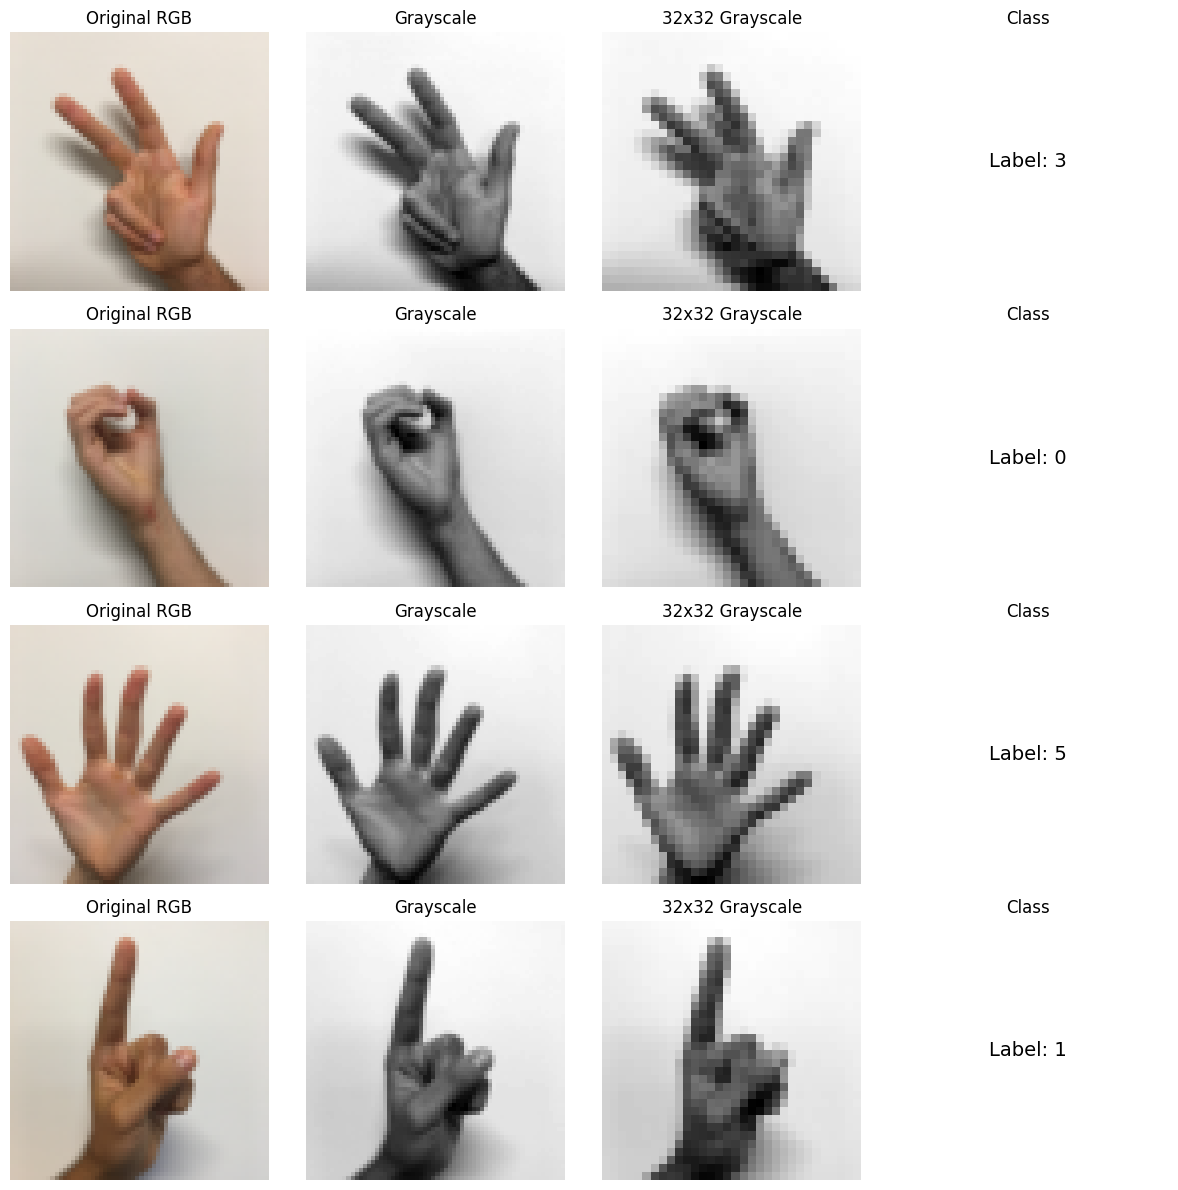

In [17]:

import cv2

# Convert RGB images to grayscale and resize to 32x32

def preprocess_images(images):
    processed = []

    for img in images:
        # RGB to grayscale
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

        # Resize to 32x32
        resized = cv2.resize(gray, (32, 32))

        processed.append(resized)

    return np.array(processed)


# Preprocess training and testing images
X_train_gray = preprocess_images(X_train)
X_test_gray = preprocess_images(X_test)


# 1. Display dimensions

print("Original training shape:", X_train.shape)
print("Original testing shape:", X_test.shape)

print("\nAfter preprocessing:")
print("X_train_gray:", X_train_gray.shape)
print("X_test_gray:", X_test_gray.shape)

print("\nImage data type:", X_train_gray.dtype)


# 2. Visualize original vs processed images

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for i in range(4):

    # Original image
    axes[i, 0].imshow(X_train[i])
    axes[i, 0].set_title("Original RGB")

    # Grayscale image
    axes[i, 1].imshow(
        cv2.cvtColor(X_train[i], cv2.COLOR_RGB2GRAY),
        cmap="gray"
    )
    axes[i, 1].set_title("Grayscale")

    # Resized image
    axes[i, 2].imshow(X_train_gray[i], cmap="gray")
    axes[i, 2].set_title("32x32 Grayscale")

    # Label
    axes[i, 3].text(
        0.5, 0.5,
        f"Label: {y_train[i]}",
        ha="center",
        va="center",
        fontsize=14
    )
    axes[i, 3].set_title("Class")

    for j in range(4):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


Run the next cell to load the "SIGNS" dataset you are going to use.

In [18]:
""" Not required anymore as I've already loaded the dataset"""


# def load_dataset():
#     train_dataset = h5py.File(r'/content/test_signs.h5', "r")
#     train_set_x_orig = np.array(train_dataset["train_set_x"][:]) # your train set features
#     train_set_y_orig = np.array(train_dataset["train_set_y"][:]) # your train set labels

#     test_dataset = h5py.File('datasets/test_signs.h5', "r")
#     test_set_x_orig = np.array(test_dataset["test_set_x"][:]) # your test set features
#     test_set_y_orig = np.array(test_dataset["test_set_y"][:]) # your test set labels

#     classes = np.array(test_dataset["list_classes"][:]) # the list of classes

#     train_set_y_orig = train_set_y_orig.reshape((1, train_set_y_orig.shape[0]))
#     test_set_y_orig = test_set_y_orig.reshape((1, test_set_y_orig.shape[0]))

#     return train_set_x_orig, train_set_y_orig, test_set_x_orig, test_set_y_orig, classes

" Not required anymore as I've already loaded the dataset"

In [19]:

# Normalize images (0-255 -> 0-1)
X_train = X_train_gray / 255.0
X_test = X_test_gray / 255.0

# Add channel dimension: (N, 32, 32) -> (N, 1, 32, 32)
X_train = np.expand_dims(X_train, axis=1)
X_test = np.expand_dims(X_test, axis=1)

# Convert to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)


# Dataset class
class SignDataset(Dataset):
    def __init__(self, X, Y):
        self.X = X
        self.Y = Y

    def __len__(self):
        return len(self.Y)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]


# Create datasets
train_dataset = SignDataset(X_train, y_train)
test_dataset = SignDataset(X_test, y_test)

print("Training:", X_train.shape, y_train.shape)
print("Testing:", X_test.shape, y_test.shape)


Training: torch.Size([96, 1, 32, 32]) torch.Size([96])
Testing: torch.Size([24, 1, 32, 32]) torch.Size([24])


TypeError: Invalid shape (1, 32, 32) for image data

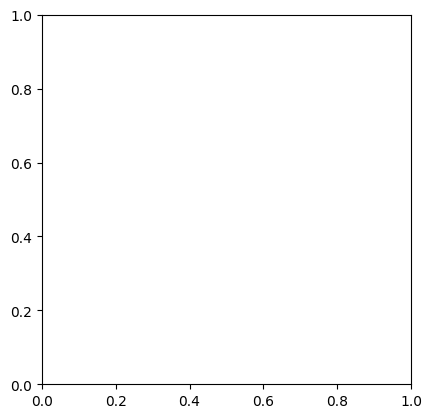

In [23]:
index = 25

plt.imshow(X_train_gray[index], cmap='gray')
plt.title(f"Label: {y_train[index]}")
plt.axis('off')
plt.show()

print("y =", y_train[index])

##  Create Placeholders (**PyTorch nn.Module Class**)

**PyTorch Note:**  PyTorch models are typically defined as a class inheriting from `nn.Module`. This class holds both the layers (parameters) and the forward pass logic. The input data is passed directly during the forward call. We'll combine placeholders, parameter initialization, and forward propagation into this class.

In [ ]:
class ConvNet(nn.Module):
    """
    Implements the CNN architecture from the assignment using PyTorch.

    Architecture: CONV2D -> RELU -> MAXPOOL -> CONV2D -> RELU -> MAXPOOL -> FLATTEN -> FULLYCONNECTED

    PyTorch's nn.Module encapsulates parameter initialization and the forward pass.
    """
    def __init__(self, num_classes=6):
        super(ConvNet, self).__init__()

        # CONV2D 1: 8 filters, F=4, S=1, Padding='SAME' (using P=1 for approximate 'SAME' behavior in a 64x64 context)
        # Input: (m, 3, 64, 64). Output: (m, 8, 63, 63)
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=8, kernel_size=4, stride=1, padding=1)
        # MAXPOOL 1: F=8, S=8. Output: (m, 8, 8, 8)
        self.pool1 = nn.MaxPool2d(kernel_size=8, stride=8)

        # CONV2D 2: 16 filters, F=2, S=1, Padding='SAME' (using P=1 for approximate 'SAME' behavior)
        # Input: (m, 8, 8, 8). Output: (m, 16, 9, 9)
        self.conv2 = nn.Conv2d(in_channels=8, out_channels=16, kernel_size=2, stride=1, padding=1)
        # MAXPOOL 2: F=4, S=4. Output: (m, 16, 2, 2)
        self.pool2 = nn.MaxPool2d(kernel_size=4, stride=4)

        # FLATTEN -> FULLYCONNECTED
        # Input features: 16 * 2 * 2 = 64
        self.fc = nn.Linear(in_features=16 * 2 * 2, out_features=num_classes)

    def forward(self, x):
        # CONV1 -> RELU -> MAXPOOL1
        x = self.conv1(x)
        x = F.relu(x)
        x = self.pool1(x)

        # CONV2 -> RELU -> MAXPOOL2
        x = self.conv2(x)
        x = F.relu(x)
        x = self.pool2(x)

        # FLATTEN -> FULLYCONNECTED
        # PyTorch uses torch.flatten (start_dim=1 to preserve batch dimension)
        F_flat = torch.flatten(x, 1)
        z = self.fc(F_flat)
        return z

##  Initialize Parameters

**PyTorch Note:** Parameters are initialized automatically when the `nn.Conv2d` and `nn.Linear` layers are defined in the `ConvNet`'s `__init__` method. The PyTorch framework handles the equivalent of `tf.get_variable`.

In [ ]:
def initialize_parameters():
    """
    In PyTorch, parameters are initialized inside the nn.Module's __init__ method.
    This function is redefined to simply print the model structure and check the parameters.
    """
    conv_model = ConvNet(num_classes=6)
    print(conv_model)
    # Example of viewing parameters
    print("Parameters:")
    for name, param in conv_model.named_parameters():
        if 'weight' in name and len(param.shape) > 1:
            print(f"{name} size: {param.size()}")

    return conv_model.state_dict()

parameters = initialize_parameters()


ConvNet(
  (conv1): Conv2d(3, 8, kernel_size=(4, 4), stride=(1, 1), padding=(1, 1))
  (pool1): MaxPool2d(kernel_size=8, stride=8, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(8, 16, kernel_size=(2, 2), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=64, out_features=6, bias=True)
)
Parameters:
conv1.weight size: torch.Size([8, 3, 4, 4])
conv2.weight size: torch.Size([16, 8, 2, 2])
fc.weight size: torch.Size([6, 64])


## Forward propagation

In PyTorch, the forward propagation logic is defined in the `forward` method of the `ConvNet` class. This function takes an input tensor $X$ and processes it through the defined layers.

In [ ]:
# The forward propagation is now implemented within the ConvNet class's forward method.
# PyTorch uses nn.Module which combines the parameter initialization and forward pass.

# Test the forward pass with a dummy tensor (adapted from original test code)
# Note: PyTorch expects channel-first (m, C, H, W)
torch.manual_seed(1)
X = torch.randn(2, 3, 64, 64) # (m, C, H, W)
conv_model = ConvNet(num_classes=6)
Z3 = conv_model(X)
print("Z3 = " + str(Z3.detach().numpy())) # print the output of the final layer

Z3 = [[ 0.15042095  0.21501657  0.08900789  0.26662612 -0.35903785  0.5884917 ]
 [ 0.10158253  0.2597984   0.1659942   0.3045144  -0.32757953  0.5790126 ]]


##  Compute Cost

The cost function is computed using **PyTorch's `nn.CrossEntropyLoss`**. This loss function is a combination of `nn.LogSoftmax` and `nn.NLLLoss`, which is the equivalent of TensorFlow's `tf.nn.softmax_cross_entropy_with_logits` when using integer class labels.

In [ ]:
def compute_cost(Z3, Y):
    """
    Computes the cost (loss) using PyTorch's CrossEntropyLoss.

    Arguments:
    Z3 -- output of the last linear unit (logits), tensor of shape (batch_size, num_classes)
    Y -- true labels, tensor of shape (batch_size,) with integer class labels

    Returns:
    cost - scalar, the cost value
    """
    cost_function = nn.CrossEntropyLoss()
    cost = cost_function(Z3, Y)

    return cost

# Test the cost function (adapted from original test code)
# Note: Z3 must be (m, num_classes), Y must be (m,) of type long
torch.manual_seed(1)
Z3 = torch.randn(4, 6, dtype=torch.float32)
Y = torch.randint(0, 6, (4,), dtype=torch.long)
cost = compute_cost(Z3, Y)
print("cost = " + str(cost.item()))

cost = 1.7490992546081543


##  Model

You are now ready to put all the pieces together into a full ConvNet model in **PyTorch**.

In [ ]:
def model(X_train, Y_train, X_test, Y_test, learning_rate = 0.009,
          num_epochs = 100, minibatch_size = 64, print_cost = True):
    """
    Implements a three-layer ConvNet in PyTorch:
    CONV2D -> RELU -> MAXPOOL -> CONV2D -> RELU -> MAXPOOL -> FLATTEN -> FULLYCONNECTED

    Arguments:
    X_train -- training set, PyTorch tensor of shape (m_train, 3, 64, 64)
    Y_train -- training labels, PyTorch tensor of shape (m_train,)
    X_test -- test set, PyTorch tensor of shape (m_test, 3, 64, 64)
    Y_test -- test labels, PyTorch tensor of shape (m_test,)
    learning_rate -- learning rate of the optimization
    num_epochs -- number of epochs of the optimization loop
    minibatch_size -- size of a minibatch
    print_cost -- True to print the cost every 5 epochs

    Returns:
    params -- the parameters learnt by the model. They are returned as a dictionary
              of PyTorch state_dict.
    """

    # ops.reset_default_graph() # TensorFlow-specific, commented out
    torch.manual_seed(1)                              # set seed
    seed = 3                                          # to keep consistent results
    m = len(X_train)
    n_y = Y_train.max().item() + 1                    # Number of classes
    costs = []                                        # To keep track of the cost

    # --- PyTorch Model Setup ---
    # Use GPU if available
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

    # 1. Initialize parameters and build the graph
    conv_model = ConvNet(num_classes=n_y).to(device)

    # 2. Define loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(conv_model.parameters(), lr=learning_rate)

    # 3. Create DataLoader
    train_dataset = SignDataset(X_train, Y_train)
    train_loader = DataLoader(train_dataset, batch_size=minibatch_size, shuffle=True)

    # --- PyTorch Training Loop ---
    print(f"Starting training on device: {device}")
    conv_model.train() # Set model to training mode

    for epoch in range(num_epochs):
        minibatch_cost = 0.
        num_minibatches = m // minibatch_size
        seed = seed + 1

        for minibatch_X, minibatch_Y in train_loader:

            # Move data to the selected device
            minibatch_X = minibatch_X.to(device)
            minibatch_Y = minibatch_Y.to(device)

            # Forward pass
            optimizer.zero_grad() # Zero the gradients
            Z3 = conv_model(minibatch_X)

            # Compute cost
            cost = criterion(Z3, minibatch_Y)

            # Backpropagation
            cost.backward()

            # Update parameters
            optimizer.step()

            minibatch_cost += cost.item() / num_minibatches

        # Print the cost every 5 epochs
        if print_cost == True and epoch % 5 == 0:
            print ("Cost after epoch %i: %f" % (epoch, minibatch_cost))
        if print_cost == True and epoch % 1 == 0:
            costs.append(minibatch_cost)

    # Plot the cost
    plt.plot(np.squeeze(costs))
    plt.ylabel('cost')
    plt.xlabel('epochs (per 5)')
    plt.title("Learning rate =" + str(learning_rate))
    plt.show()

    # --- PyTorch Prediction and Evaluation ---
    conv_model.eval() # Set model to evaluation mode
    with torch.no_grad(): # Disable gradient calculations during inference

        # Training set accuracy
        X_train_device = X_train.to(device)
        Y_train_device = Y_train.to(device)
        Z3_train = conv_model(X_train_device)
        train_predictions = torch.argmax(Z3_train, dim=1)
        train_accuracy = (train_predictions == Y_train_device).float().mean().item()

        # Test set accuracy
        X_test_device = X_test.to(device)
        Y_test_device = Y_test.to(device)
        Z3_test = conv_model(X_test_device)
        test_predictions = torch.argmax(Z3_test, dim=1)
        test_accuracy = (test_predictions == Y_test_device).float().mean().item()

    print("Train Accuracy: %f" % train_accuracy)
    print("Test Accuracy: %f" % test_accuracy)

    return conv_model.state_dict() # Return PyTorch parameters

Starting training on device: cpu
Cost after epoch 0: 1.911568
Cost after epoch 5: 1.904816
Cost after epoch 10: 1.904138
Cost after epoch 15: 1.904316
Cost after epoch 20: 1.904642
Cost after epoch 25: 1.904358
Cost after epoch 30: 1.904429
Cost after epoch 35: 1.904298
Cost after epoch 40: 1.904724
Cost after epoch 45: 1.904393
Cost after epoch 50: 1.904188
Cost after epoch 55: 1.904385
Cost after epoch 60: 1.904205
Cost after epoch 65: 1.904195
Cost after epoch 70: 1.904112
Cost after epoch 75: 1.904767
Cost after epoch 80: 1.904267
Cost after epoch 85: 1.905303
Cost after epoch 90: 1.904503
Cost after epoch 95: 1.904227


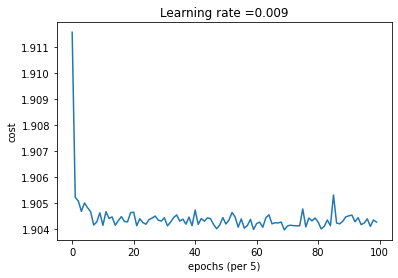

Train Accuracy: 0.166667
Test Accuracy: 0.166667


In [ ]:
# The accuracy will be printed inside the model function call
parameters = model(X_train, Y_train, X_test, Y_test)

## Test with your own image


If you want, you can also load your own image and see what your model predicts. To do this, follow these steps:

1.  Click on "File" -> "Open" at the upper left of the notebook.
2.  Click on "Upload" near the top right, and upload your image.
3.  Change the name of your image in the following code
4.  Run the code and check the prediction.

*(Optional) If you get an error trying to in read your image, you might need to try a different image file. For example, JPG files produced by Mac iPhone seem to require a special conversion process and are not easily compatible with `scipy.ndimage`.*

In [ ]:
def predict_pytorch(X, parameters):
    """
    Predicts the output of the ConvNet using the given parameters (state_dict).

    Arguments:
    X -- input data, PyTorch tensor of shape (m, 3, 64, 64)
    parameters -- dictionary of PyTorch model state_dict

    Returns:
    y_pred -- array of predictions (class labels)
    """
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

    # Initialize model and load parameters
    conv_model = ConvNet(num_classes=6).to(device)
    conv_model.load_state_dict(parameters)
    conv_model.eval()

    # Perform inference
    with torch.no_grad():
        X_device = X.to(device)
        Z3 = conv_model(X_device)
        y_pred = torch.argmax(Z3, dim=1).cpu().numpy()

    return y_pred

In [ ]:
my_image = "thumbs_up.jpg"

fname = "images/" + my_image

image = np.array(ndimage.imread(fname, flatten=False))
my_image = scipy.misc.imresize(image, size=(64,64))
plt.imshow(my_image)

# Preprocess for PyTorch prediction:
my_image_float = my_image.astype(np.float32) / 255.
# Reshape to (1, C, H, W)
my_image_reshaped = np.transpose(my_image_float, (2, 0, 1))[np.newaxis, ...]
my_image_tensor = torch.tensor(my_image_reshaped, dtype=torch.float32)

# Call the PyTorch prediction function
my_image_prediction = predict_pytorch(my_image_tensor, parameters)

print("Your algorithm predicts: y = " + str(np.squeeze(my_image_prediction)))
plt.title("Your algorithm predicts: y = " + str(np.squeeze(my_image_prediction)))

In [ ]:
fname = "images/thumbs_up.jpg"
image = np.array(ndimage.imread(fname, flatten=False))
my_image = scipy.misc.imresize(image, size=(64,64))
plt.imshow(my_image)